# 5.5.4 — Assentamentos da Reforma Agrária: tabelas e mapas

Este notebook produz a **tabela completa por assentamento**, o mapa geral com contornos reforçados, o mapa da **UF com mais registros** e os mapas dos **dois assentamentos com mais registros**. Também reproduz a tabela por categoria de produtor e gera tabelas por ano e por assentamento × categoria.

**Execução:** abra no Colab, selecione **Ambiente de execução → Executar tudo** e autorize a montagem do Drive. Os caminhos da versão 2 já estão preenchidos. A origem tem aproximadamente **583 MB**; a leitura sequencial e o cache evitam carregar todas as cópias de polígonos simultaneamente. Os resultados ficam em `complementos_assentamentos_5_5_4/<data_hora>`.

**Diferença importante em relação ao resumo anterior:** a tabela V2 por unidade tem 2.455 linhas para 1.568 IDs, pois subdivide assentamentos por categoria de produtor. Aqui cada ID recebe uma única linha. Registros e área acumulada podem ser somados entre essas subdivisões; **glebas distintas, referências BACEN e área da união precisam ser recalculadas a partir dos registros**.

Nos resumos conferidos em 18/09/2026, a consolidação por ID aponta PA Teijin (795 registros) e PA Itamarati - AMFFI (639) como os dois primeiros. O resumo estadual anterior aponta Goiás (8.613 registros). Esses números são referências: o notebook recalcula os rankings e registra eventuais diferenças do recorte estadual.

**Interpretação:** assentamentos são uma camada de controle territorial nesta pesquisa; a interseção não é tratada como impedimento automático ao crédito. Categoria de produtor não é modalidade de assentamento. Os códigos de situação são preservados literalmente, sem interpretação jurídica não documentada. Os mapas distinguem limite do assentamento (azul), gleba completa (laranja) e interseção (vermelho).

Reparos de validade **após reprojeção**, quando necessários, são permitidos apenas nos limites usados para desenho e registrados no cache e nas saídas de cada execução. As interseções usadas nos cálculos continuam sob validação rigorosa. Nenhuma linha administrativa é eliminada por repetição de REF_BACEN ou id_gleba2.

## 1. Preparar o Colab e montar o Drive

In [1]:
%pip -q install "geopandas>=1.0,<2" "shapely>=2.0,<3" "pyogrio>=0.9" "pyproj>=3.6" openpyxl requests tqdm
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Caminhos e parâmetros
A origem é a base de registros espaciais, não a base expandida por partes municipais. Se os arquivos forem movidos, altere apenas os caminhos abaixo. O CRS do WKT deve corresponder ao usado na versão 2.
O arquivo tem 583.434.677 bytes na versão conferida. As geometrias completas serão identificadas no cabeçalho; não é necessário preencher manualmente a coluna quando existe uma candidata única.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
RAIZ = Path('/content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios')
PASTA_V2 = RAIZ / 'intersecoes' / 'assentamentos' / 'resultados_por_id_gleba2' / 'versao_2'
ARQUIVO_BASE = PASTA_V2 / 'bases_analiticas' / 'base_registros_espaciais_sem_deduplicacao.csv'
ID_DRIVE_BASE = '1uYD_zMagSFKhE7kO_-8yhUZXcgMvz4At'
ARQUIVO_UFS = None       # opcional: caminho de ZIP, SHP, GPKG ou GeoJSON
ARQUIVO_BIOMAS = None    # opcional: caminho de ZIP, SHP, GPKG ou GeoJSON
FONTE_UFS = 'IBGE, Malha de Unidades da Federação, 2024'
FONTE_BIOMAS = 'IBGE, Biomas do Brasil, 2019, escala 1:250.000'
URL_UFS = 'https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2024/Brasil/BR_UF_2024.zip'
URL_BIOMAS = 'https://geoftp.ibge.gov.br/informacoes_ambientais/estudos_ambientais/biomas/vetores/Biomas_250mil.zip'
COLUNA_UF = 'SIGLA_UF'
COLUNA_BIOMA = 'Bioma'
CRS_WKT = 'EPSG:4674'
CRS_ANALISE = 'EPSG:5880'
ANOS = [2021, 2022, 2023, 2024, 2025]
NUMERO_TERRITORIOS_DETALHE = 2
DPI = 400
FORMATOS = ['png', 'pdf', 'svg']
MOSTRAR_FIGURAS = True
BAIXAR_ZIP = True
TOLERANCIA_AREA_HA = 0.05
REFERENCIA = dict(registros=33044,glebas=24615,territorios=1568,refs=26281,
    area_acumulada_ha=646622.7309821949,area_uniao_ha=291757.1874852057,
    soma_valores_linhas=5892958982.97)
# Descoberta automática da coluna com o polígono completo do assentamento.
# Preencha somente se o notebook informar mais de uma candidata.
COLUNA_GEOMETRIA_ASSENTAMENTO = None
SIMPLIFICACAO_GERAL_M = 150
SIMPLIFICACAO_ESTADO_M = 30
RECRIAR_CACHE = False
VERSAO_CACHE = 'as554_v2_reparos'
EXECUCAO = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
SAIDA = RAIZ / 'complementos_assentamentos_5_5_4' / EXECUCAO
CACHE = RAIZ / 'complementos_assentamentos_5_5_4' / '_cache'
for p in [SAIDA,CACHE,SAIDA/'tabelas',SAIDA/'mapas']:p.mkdir(parents=True,exist_ok=True)
print('Base:',ARQUIVO_BASE)
print('Resultados:',SAIDA)

ARQUIVO_RESUMO_UNIDADES = PASTA_V2 / 'tabelas' / '04_resumo_por_unidade_territorial.csv'

ARQUIVO_RESUMO_PRODUTOR = PASTA_V2 / 'tabelas' / '11_resumo_por_tipo_produtor.csv'


Base: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/assentamentos/resultados_por_id_gleba2/versao_2/bases_analiticas/base_registros_espaciais_sem_deduplicacao.csv
Resultados: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/complementos_assentamentos_5_5_4/20260918_134855_119125


## 3. Contexto cartográfico
Limites de UFs e bioma são obtidos do IBGE. São preservados os polígonos dos assentamentos da versão 2, evitando misturar versões territoriais. O arquivo grande é identificado por caminho, tamanho e data de modificação; não é relido apenas para calcular um hash integral.

In [3]:
import json, hashlib, zipfile, re, math, platform, textwrap
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import box
from pyproj import CRS, Transformer, Geod
import requests
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from IPython.display import display
ORIGENS={}

def hash_arquivo(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
    return h.hexdigest()

def entrada_drive():
    if not ARQUIVO_BASE.is_file():
        raise FileNotFoundError('Base não encontrada no Drive montado: '+str(ARQUIVO_BASE)+
            '\nConfira a conta e o caminho. ID do arquivo conferido: '+ID_DRIVE_BASE)
    return ARQUIVO_BASE

def obter_vetor(local,url,nome):
    if local:
        p=Path(local)
        if not p.is_file():raise FileNotFoundError(p)
        return p
    p=CACHE/nome
    if not (p.is_file() and zipfile.is_zipfile(p)):
        tmp=p.with_suffix('.part')
        with requests.get(url,stream=True,timeout=(30,180)) as r:
            r.raise_for_status()
            with tmp.open('wb') as f:
                for b in r.iter_content(1024*1024):f.write(b)
        if not zipfile.is_zipfile(tmp):raise ValueError('O download não retornou ZIP: '+url)
        tmp.replace(p)
    return p

def ler_vetor(p):
    z=gpd.read_file('zip://'+str(p) if str(p).lower().endswith('.zip') else p)
    if z.crs is None:raise ValueError('Vetor sem referência espacial: '+str(p))
    return z

CAMINHO=entrada_drive()
pufs=obter_vetor(ARQUIVO_UFS,URL_UFS,'BR_UF_2024.zip')
pbiomas=obter_vetor(ARQUIVO_BIOMAS,URL_BIOMAS,'Biomas_250mil_2019.zip')
for nome,p in [('base',CAMINHO),('ufs',pufs),('biomas',pbiomas)]:
    ORIGENS[nome]={'arquivo':str(p),'bytes':p.stat().st_size,'mtime_ns':p.stat().st_mtime_ns}
    if nome!='base':ORIGENS[nome]['sha256']=hash_arquivo(p)
ufs=ler_vetor(pufs);biomas=ler_vetor(pbiomas)
if COLUNA_UF not in ufs or COLUNA_BIOMA not in biomas:raise ValueError('Confira as colunas dos arquivos de contexto.')
ufs=ufs[[COLUNA_UF,'geometry']].rename(columns={COLUNA_UF:'UF'}).to_crs(CRS_ANALISE)
ufs['UF']=ufs.UF.astype(str).str.strip()
if ufs.UF.duplicated().any():ufs=ufs.dissolve(by='UF',as_index=False)
cer=biomas.loc[biomas[COLUNA_BIOMA].astype(str).str.strip().str.casefold().eq('cerrado'),['geometry']].to_crs(CRS_ANALISE)
if cer.empty:raise ValueError('Cerrado não encontrado no vetor de biomas.')
# Reparos apenas nos limites de contexto; qualquer alteração fica registrada.
ORIGENS['reparos_contexto']={}
for nome,z in [('ufs',ufs),('cerrado',cer)]:
    if z.geometry.isna().any() or z.geometry.is_empty.any():raise ValueError('Geometria ausente no contexto '+nome)
    mask=~z.is_valid;ORIGENS['reparos_contexto'][nome]=int(mask.sum())
    if mask.any():z.loc[mask,'geometry']=z.loc[mask,'geometry'].make_valid()
    if not z.geom_type.isin(['Polygon','MultiPolygon']).all():raise ValueError('Contexto não poligonal: '+nome)
cerrado=cer.geometry.union_all()
print('Entradas localizadas. Base:',round(CAMINHO.stat().st_size/1e9,2),'GB; leitura sequencial na próxima célula.')


Entradas localizadas. Base: 0.58 GB; leitura sequencial na próxima célula.


## 4. Leitura sequencial, cache e validação

Cado assentamento e cada gleba têm uma cópia geométrica no cache; todas as linhas de interseção são preservadas. Ausências, divergências entre cópias e anos fora de 2021–2025 interrompem a leitura com diagnóstico.

Polígonos válidos na origem podem apresentar problemas após reprojeção. Para os limites destinados ao **desenho**, o notebook aplica `make_valid`, retém os componentes poligonais e registra motivo e área antes/depois. Isso não altera as interseções de cálculo. Os registros de reparo são exportados também quando um cache é reutilizado. Geometrias inválidas na origem e interseções inválidas continuam exigindo diagnóstico; não são excluídas nem corrigidas silenciosamente.

In [4]:
import csv as csvmod, sqlite3, zlib, tempfile, shutil, time
from shapely.ops import transform as transformar
from tqdm.auto import tqdm
csvmod.field_size_limit(2**31-1)

def numero_pt(v):
    s=str(v).strip()
    if s.lower() in ['', 'nan', 'none', 'null', '<na>']:return np.nan
    if ',' in s:s=s.replace('.','').replace(',','.')
    try:
        a=float(s)
        if not np.isfinite(a):raise ValueError(s)
        return a
    except ValueError:raise ValueError('Número não interpretável: '+s)

def csv(t,n):
    t.to_csv(SAIDA/'tabelas'/n,index=False,sep=';',decimal=',',encoding='utf-8-sig',float_format='%.9f')

with CAMINHO.open('r',encoding='utf-8-sig',newline='') as f:
    cabecalho=next(csvmod.reader(f,delimiter=';'))
if len(cabecalho)!=len(set(cabecalho)):raise ValueError('Há nomes de colunas duplicados no CSV.')
C={'gleba':'ID_GLEBA2','ref':'REF_BACEN','ano':'ANO_BASE','unidade':'ASSENT_ID_INTERNO',
   'nome':'ASSENT_NOME_PROJE','situacao_codigo':'ASSENT_FASE','uf_territorio':'ASSENT_UF',
   'forma_obtencao':'ASSENT_FORMA_OBTE','produtor_original':'TIPO_PRODUTOR_ANALISE','valor':'VL_PARC_CREDITO',
   'area_csv':'AREA_INTERSECAO_HA','inter':'GEOMETRIA_INTERSECAO_WKT','geom_gleba':'GT_GEOMETRIA'}
# Campos administrativos conferidos no arquivo 01_campos_identificados.csv da V2.
# A geometria territorial completa é descoberta no cabeçalho sem carregar os 583 MB.
if COLUNA_GEOMETRIA_ASSENTAMENTO:
    C['geom_territorio']=COLUNA_GEOMETRIA_ASSENTAMENTO
else:
    conhecidas=['GEOMETRIA_ASSENTAMENTO_WKT','GEOMETRIA_ASSENTAMENTOS_WKT',
                'GEOMETRIA_ASSENT_WKT','ASSENT_GEOMETRIA_WKT','ASSENT_GEOMETRIA']
    candidatas=[c for c in cabecalho if c in conhecidas or
        ('GEOMETR' in c.upper() and 'ASSENT' in c.upper())]
    candidatas=list(dict.fromkeys(candidatas))
    if len(candidatas)!=1:
        (SAIDA/'cabecalho_base.txt').write_text('\n'.join(cabecalho),encoding='utf-8')
        raise ValueError('Não foi possível selecionar uma única geometria COMPLETA do assentamento. '
            'Candidatas: '+str(candidatas)+'. Veja cabecalho_base.txt e preencha COLUNA_GEOMETRIA_ASSENTAMENTO. '
            'Não use GEOMETRIA_INTERSECAO_WKT em seu lugar.')
    C['geom_territorio']=candidatas[0]
C['linha']='_ID_LINHA_ORIGINAL' if '_ID_LINHA_ORIGINAL' in cabecalho else None
faltam=set(v for v in C.values() if v)-set(cabecalho)
if faltam:raise ValueError('Colunas obrigatórias ausentes: '+str(sorted(faltam)))
if C['geom_territorio'] in [C['inter'],C['geom_gleba']]:raise ValueError('Coluna do assentamento não pode ser a interseção ou a gleba.')
ORIGENS['identificador_linha']=C['linha'] or 'posição sequencial no CSV de registros espaciais'
assinatura={'origem':ORIGENS['base'],'colunas':C,'anos':ANOS,'crs_wkt':CRS_WKT,
            'crs_analise':CRS_ANALISE,'versao':VERSAO_CACHE}
chave=hashlib.sha256(json.dumps(assinatura,sort_keys=True).encode()).hexdigest()[:20]
BANCO=CACHE/f'assentamentos_reduzido_{chave}.sqlite'
converter=Transformer.from_crs(CRS_WKT,CRS_ANALISE,always_xy=True).transform

REPAROS_CARTOGRAFICOS=[]

def poligono(wkt,identificacao):
    if not str(wkt).strip():raise ValueError('Geometria ausente: '+identificacao)
    g=shapely.force_2d(shapely.from_wkt(wkt,on_invalid='raise'))
    if g is None or g.is_empty or g.geom_type not in ('Polygon','MultiPolygon'):
        raise ValueError('Geometria vazia ou não poligonal: '+identificacao)
    if not g.is_valid:
        raise ValueError('Geometria inválida na origem: '+identificacao+'; '+shapely.is_valid_reason(g))
    a,b,c,d=g.bounds
    if not np.isfinite([a,b,c,d]).all():raise ValueError('Coordenadas não finitas: '+identificacao)
    if CRS.from_user_input(CRS_WKT).is_geographic and not (-80<a<-30 and -40<b<10 and -80<c<-30 and -40<d<10):
        raise ValueError('Coordenadas incompatíveis com WKT geográfico do Brasil: '+identificacao)
    g=transformar(converter,g)
    if not np.isfinite(g.bounds).all() or not np.isfinite(g.area):
        raise ValueError('Reprojeção não finita: '+identificacao+'. Confira os CRS.')
    if not g.is_valid:
        motivo=shapely.is_valid_reason(g)
        if not identificacao.startswith(('territorio=','gleba=')):
            raise ValueError('Interseção inválida após reprojeção: '+identificacao+'; '+motivo)
        antes=float(g.area);pilha=[shapely.make_valid(g)];partes=[];descartados=[]
        while pilha:
            parte=pilha.pop()
            if parte.is_empty:continue
            if parte.geom_type=='Polygon':partes.append(parte)
            elif parte.geom_type in ('MultiPolygon','GeometryCollection'):pilha.extend(parte.geoms)
            else:descartados.append(parte.geom_type)
        if not partes:raise ValueError('Reparo sem componente poligonal: '+identificacao)
        g=shapely.union_all(partes)
        if g.is_empty or not g.is_valid or g.geom_type not in ('Polygon','MultiPolygon') or not np.isfinite(g.area) or g.area<=0:
            raise ValueError('Reparo cartográfico não recuperável: '+identificacao)
        REPAROS_CARTOGRAFICOS.append({'identificacao':identificacao,'motivo':motivo,
            'area_antes_ha':antes/10000,'area_depois_ha':float(g.area)/10000,
            'diferenca_area_ha':(float(g.area)-antes)/10000,'componentes_descartados':','.join(descartados)})
        print('Reparo de desenho documentado:',identificacao)
    if g.is_empty or g.area<=0:raise ValueError('Geometria sem área positiva: '+identificacao)
    return g

def compactar(g):return sqlite3.Binary(zlib.compress(shapely.to_wkb(g),level=1))
def descompactar(v):return shapely.from_wkb(zlib.decompress(v))

def cache_pronto(p):
    if not p.is_file():return False
    try:
        with sqlite3.connect(p) as db:
            r=db.execute('SELECT valor FROM meta WHERE chave="assinatura"').fetchone()
            ok=db.execute('SELECT valor FROM meta WHERE chave="completo"').fetchone()
            return r is not None and json.loads(r[0])==assinatura and ok is not None and ok[0]=='sim'
    except (sqlite3.Error,ValueError):return False

def construir_cache(origem,destino):
    REPAROS_CARTOGRAFICOS.clear()
    vistos={};atributos_vistos={};linhas_vistas=set();variantes=0
    inicio=time.monotonic();numero=0;linha_id=None;unidade=None;gleba=None
    # Banco intermediário em disco local: evita milhares de pequenas escritas no Drive.
    with tempfile.TemporaryDirectory(prefix='assentamentos_553_') as td:
        temporario=Path(td)/'cache.sqlite'
        db=sqlite3.connect(temporario)
        try:
            db.executescript('''
                CREATE TABLE geometrias (tipo TEXT, id TEXT, atributos TEXT, wkb BLOB, PRIMARY KEY(tipo,id));
                CREATE TABLE registros (numero INTEGER PRIMARY KEY, atributos TEXT, wkb BLOB);
                CREATE TABLE meta (chave TEXT PRIMARY KEY, valor TEXT);
            ''')
            def guardar_unica(tipo,ident,wkt,attrs):
                nonlocal variantes
                key=(tipo,ident);h=hashlib.sha256(wkt.encode('utf-8')).hexdigest()
                attrs_str=json.dumps(attrs,sort_keys=True,ensure_ascii=False)
                if key in vistos:
                    if atributos_vistos[key]!=attrs_str:raise ValueError('Atributos divergentes para '+tipo+'='+ident)
                    if h in vistos[key]:return
                    original=descompactar(db.execute('SELECT wkb FROM geometrias WHERE tipo=? AND id=?',key).fetchone()[0])
                    if not original.equals(poligono(wkt,tipo+'='+ident)):
                        raise ValueError('Cópias geométricas divergentes para '+tipo+'='+ident)
                    vistos[key].add(h);variantes+=1;return
                g=poligono(wkt,tipo+'='+ident)
                db.execute('INSERT INTO geometrias VALUES (?,?,?,?)',(tipo,ident,attrs_str,compactar(g)))
                vistos[key]={h};atributos_vistos[key]=attrs_str
            with origem.open('r',encoding='utf-8-sig',newline='') as f:
                reader=csvmod.DictReader(f,delimiter=';')
                for numero,row in enumerate(tqdm(reader,total=REFERENCIA['registros'],desc='Leitura sequencial',unit='linha'),1):
                    if None in row or any(v is None for v in row.values()):raise ValueError('Quantidade de campos diferente do cabeçalho.')
                    attrs={k:str(row[v]).strip() for k,v in C.items() if v and k not in ('inter','geom_gleba','geom_territorio','valor','area_csv')}
                    linha_id=attrs.get('linha',str(numero));attrs['linha']=linha_id
                    for k in ['linha','unidade','gleba','ref','ano']:
                        if attrs[k].lower() in ('','nan','none','null','<na>'):raise ValueError('Identificador ausente: '+k)
                    unidade=attrs['unidade'];gleba=attrs['gleba']
                    if linha_id in linhas_vistas:raise ValueError('ID de linha repetido; confira se a origem é a base de partes municipais.')
                    linhas_vistas.add(linha_id)
                    ano=numero_pt(attrs['ano'])
                    if ano not in ANOS:raise ValueError('Ano fora de 2021–2025: '+attrs['ano'])
                    attrs['ano']=str(int(ano));attrs['codigo_territorio']=unidade
                    for k in ['nome','situacao_codigo','uf_territorio','forma_obtencao','produtor_original']:
                        if attrs[k].lower() in ('','nan','none','null','<na>'):
                            attrs[k]='Sem denominação — ID '+unidade if k=='nome' else 'Não informado'
                    for campo_epsg in ['ASSENT_EPSG']:
                        if campo_epsg in row and str(row[campo_epsg]).strip():
                            if numero_pt(row[campo_epsg])!=CRS.from_user_input(CRS_WKT).to_epsg():
                                raise ValueError(campo_epsg+' diverge do CRS_WKT configurado.')
                    attrs['valor']=numero_pt(row[C['valor']]);attrs['area_csv']=numero_pt(row[C['area_csv']])
                    if not np.isfinite(attrs['area_csv']):raise ValueError('Área de origem ausente.')
                    attrs_territorio={k:attrs[k] for k in ['unidade','codigo_territorio','nome','situacao_codigo','uf_territorio','forma_obtencao']}
                    guardar_unica('territorio',unidade,row[C['geom_territorio']],attrs_territorio)
                    guardar_unica('gleba',gleba,row[C['geom_gleba']],{'gleba':gleba})
                    g=poligono(row[C['inter']],'interseção, linha '+linha_id)
                    attrs['area_ha']=g.area/10000
                    db.execute('INSERT INTO registros VALUES (?,?,?)',(numero,json.dumps(attrs,ensure_ascii=False),compactar(g)))
                    if numero%500==0:db.commit()
            if numero==0:raise ValueError('Base vazia.')
            info={'linhas':numero,'variantes_wkt_equivalentes':variantes,'duracao_segundos':time.monotonic()-inicio,'reparos_cartograficos':list(REPAROS_CARTOGRAFICOS)}
            for k,v in [('assinatura',json.dumps(assinatura)),('completo','sim'),('leitura',json.dumps(info))]:
                db.execute('INSERT INTO meta VALUES (?,?)',(k,v))
            db.commit()
            if db.execute('PRAGMA quick_check').fetchone()[0]!='ok':raise RuntimeError('Falha na integridade do cache.')
        except Exception as exc:
            diagnostico={'linha_sequencial':numero,'linha_id':linha_id,'unidade':unidade,'gleba':gleba,'erro':str(exc)}
            (SAIDA/'diagnostico_leitura.json').write_text(json.dumps(diagnostico,ensure_ascii=False,indent=2),encoding='utf-8')
            raise
        finally:db.close()
        incompleto=destino.with_suffix('.part')
        shutil.copyfile(temporario,incompleto)
        if incompleto.stat().st_size!=temporario.stat().st_size:raise RuntimeError('Cópia incompleta do cache.')
        incompleto.replace(destino)
    print('Cache reduzido salvo:',destino,'—',round(destino.stat().st_size/1e6,1),'MB')

if RECRIAR_CACHE or not cache_pronto(BANCO):construir_cache(CAMINHO,BANCO)
else:print('Reutilizando cache concluído e compatível:',BANCO.name)

def carregar_geometrias(tipo,ids=None,simplificar=0):
    escolhidos=None if ids is None else set(map(str,ids));result=[]
    with sqlite3.connect(BANCO) as db:
        # Filtra por ID antes de descompactar geometrias não solicitadas.
        for ident,attrs,wkb in db.execute('SELECT id,atributos,wkb FROM geometrias WHERE tipo=?',(tipo,)):
            if escolhidos is not None and ident not in escolhidos:continue
            g=descompactar(wkb)
            if simplificar:g=g.simplify(simplificar,preserve_topology=True)
            result.append({**json.loads(attrs),'geometry':g})
    if not result:return gpd.GeoDataFrame({'geometry':[]},crs=CRS_ANALISE)
    return gpd.GeoDataFrame(result,geometry='geometry',crs=CRS_ANALISE)

reg=[]
with sqlite3.connect(BANCO) as db:
    for attrs,wkb in db.execute('SELECT atributos,wkb FROM registros ORDER BY numero'):
        reg.append({**json.loads(attrs),'geometry':descompactar(wkb)})
    ORIGENS['leitura_cache']=json.loads(db.execute('SELECT valor FROM meta WHERE chave="leitura"').fetchone()[0])
x=gpd.GeoDataFrame(reg,geometry='geometry',crs=CRS_ANALISE);del reg
# Estas duas coleções servem apenas ao desenho de visão geral; os originais estão no cache.
territorios=carregar_geometrias('territorio',simplificar=SIMPLIFICACAO_GERAL_M)
glebas=carregar_geometrias('gleba',simplificar=SIMPLIFICACAO_GERAL_M)
area_check=x[['linha','unidade','gleba','area_csv','area_ha']].copy()
area_check['diferenca_ha']=area_check.area_ha-area_check.area_csv
csv(area_check,'conferencia_areas_por_linha.csv')
if area_check.diferenca_ha.abs().max()>TOLERANCIA_AREA_HA:
    raise ValueError('Área calculada diverge da V2 em alguma linha. Confira CRS e conferencia_areas_por_linha.csv.')
auditoria_nomes=territorios.drop(columns='geometry').copy()
csv(auditoria_nomes,'identificacao_assentamentos.csv')
print(f'{len(x):,} linhas preservadas; {len(glebas):,} glebas; {len(territorios):,} assentamentos.'.replace(',','.'))
print('Coluna de limite completo:',C['geom_territorio'])

# Exporta os reparos da execução de origem do cache, inclusive quando ele é reutilizado.
reparos=pd.DataFrame(ORIGENS['leitura_cache'].get('reparos_cartograficos',[]),columns=[
 'identificacao','motivo','area_antes_ha','area_depois_ha','diferenca_area_ha','componentes_descartados'])
csv(reparos,'reparos_geometrias_desenho.csv')
(SAIDA/'reparos_geometrias_desenho.json').write_text(reparos.to_json(orient='records',force_ascii=False,indent=2),encoding='utf-8')
print('Reparos cartográficos documentados:',len(reparos))


Leitura sequencial:   0%|          | 0/33044 [00:00<?, ?linha/s]

Reparo de desenho documentado: territorio=6554
Reparo de desenho documentado: gleba=381430
Reparo de desenho documentado: gleba=475879
Cache reduzido salvo: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/complementos_assentamentos_5_5_4/_cache/assentamentos_reduzido_9bb994fe720253393e34.sqlite — 34.2 MB
33.044 linhas preservadas; 24.615 glebas; 1.568 assentamentos.
Coluna de limite completo: GEOMETRIA_ASSENTAMENTO_WKT
Reparos cartográficos documentados: 3


## 5. Consolidar por assentamento e analisar categorias de produtor

A consolidação usa `ASSENT_ID_INTERNO`. Categoria de produtor é atributo de cada registro, podendo variar dentro do mesmo assentamento. Por isso, ela não é usada como atributo fixo do polígono nem como modalidade territorial.

O resumo antigo é agregado por ID **apenas para registros e área acumulada**. Quando uma unidade aparece em mais de uma linha do resumo, não se comparam somas de glebas ou de uniões com os novos totais: essas medidas são recalculadas nos dados originais. Os códigos de `ASSENT_FASE` permanecem sem tradução.

In [5]:
def metricas(z):
    return dict(registros=len(z),glebas=z.gleba.nunique(),refs=z.ref.nunique(),
        area_acumulada_ha=float(z.area_ha.sum()),area_uniao_ha=float(z.geometry.union_all().area/10000),
        soma_valores_linhas=float(z.valor.sum(min_count=1)),linhas_sem_valor=int(z.valor.isna().sum()))
res=[]
for unidade,z in tqdm(x.groupby('unidade',sort=False),total=x.unidade.nunique(),desc='Totais por assentamento'):
    t=territorios.loc[territorios.unidade.eq(unidade)].iloc[0]
    res.append({'unidade':unidade,'codigo_territorio':t.codigo_territorio,'nome':t['nome'],'situacao_codigo':t.situacao_codigo,'forma_obtencao':t.forma_obtencao,'uf_territorio':t.uf_territorio,**metricas(z)})
por_territorio=pd.DataFrame(res).sort_values(['registros','nome','unidade'],ascending=[False,True,True]).reset_index(drop=True)
por_territorio.insert(0,'posicao',np.arange(1,len(por_territorio)+1))
geral={**metricas(x),'territorios':len(territorios)}
controle=[]
for k,anterior in REFERENCIA.items():
    valor=geral[k];tol=TOLERANCIA_AREA_HA if k.startswith('area') else (0.02 if k=='soma_valores_linhas' else 0)
    controle.append({'indicador':k,'calculado':valor,'referencia_v2':anterior,'diferenca':valor-anterior,'confere':abs(valor-anterior)<=tol})
conferencia=pd.DataFrame(controle)
csv(conferencia,'conferencia_com_texto_5_5_4.csv')
if not conferencia.confere.all():
    print('ATENÇÃO: há divergências com a versão anterior; os produtos usarão os resultados calculados, sem forçar os totais.')
assert por_territorio.registros.sum()==len(x)
assert np.isclose(por_territorio.area_acumulada_ha.sum(),geral['area_acumulada_ha'])
csv(por_territorio,'totais_por_assentamento_publica_completo.csv')
csv(pd.DataFrame([geral]),'totais_gerais.csv')
TOP_TERRITORIOS=por_territorio.head(NUMERO_TERRITORIOS_DETALHE).unidade.tolist()
display(conferencia);display(por_territorio.head(20))
print('territórios para mapas individuais:',por_territorio.head(NUMERO_TERRITORIOS_DETALHE)[['nome','situacao_codigo','registros']].to_dict('records'))

# Categoria do produtor é atributo de cada linha, não uma modalidade do assentamento.
import unicodedata

def categoria_produtor(v):
    s=str(v).strip()
    chave=unicodedata.normalize('NFKD',s).encode('ascii','ignore').decode().casefold()
    if 'pronaf' in chave or chave in ('pequeno produtor','pequenos produtores'):return 'Pronaf'
    if 'pronamp' in chave or chave in ('medio produtor','medios produtores'):return 'Pronamp'
    if 'demais' in chave or chave in ('grande produtor','grandes produtores'):return 'Demais Produtores'
    if chave in ('','nan','none','null','nao informado'):return 'Não informado'
    return 'Não classificado: '+s

x['categoria_produtor']=x.produtor_original.map(categoria_produtor)
auditoria_produtor=x[['produtor_original','categoria_produtor']].drop_duplicates().sort_values('produtor_original')
csv(auditoria_produtor,'auditoria_padronizacao_categoria_produtor.csv')
por_categoria=pd.DataFrame([{'categoria_produtor':cat,'territorios':z.unidade.nunique(),**metricas(z)}
    for cat,z in x.groupby('categoria_produtor')]).sort_values('registros',ascending=False)
csv(por_categoria,'totais_por_categoria_produtor.csv')
por_ano=pd.DataFrame([{'ano':ano,'territorios':z.unidade.nunique(),**metricas(z)} for ano,z in x.groupby('ano')]).sort_values('ano')
csv(por_ano,'totais_por_ano.csv')
por_situacao=pd.DataFrame([{'situacao_codigo':cod,'territorios':z.unidade.nunique(),**metricas(z)}
    for cod,z in x.groupby('situacao_codigo')]).sort_values('registros',ascending=False)
csv(por_situacao,'totais_por_codigo_situacao_sem_interpretacao.csv')
por_assentamento_categoria=pd.DataFrame([
    {'unidade':ident,'categoria_produtor':cat,**metricas(z)}
    for (ident,cat),z in tqdm(x.groupby(['unidade','categoria_produtor']),desc='Assentamento × categoria')])
por_assentamento_categoria=por_assentamento_categoria.merge(por_territorio[['unidade','nome']],on='unidade',how='left')
csv(por_assentamento_categoria,'totais_por_assentamento_e_categoria.csv')

# O resumo V2 tem mais de uma linha para alguns IDs. Não somar medidas não aditivas.
controle_unidades=pd.DataFrame();resumo_antigo=pd.DataFrame()
if ARQUIVO_RESUMO_UNIDADES.is_file():
    anterior=pd.read_csv(ARQUIVO_RESUMO_UNIDADES,sep=';',encoding='utf-8-sig',dtype=str,keep_default_na=False)
    conv={'_UNIDADE_ID':'unidade','_UNIDADE_NOME':'nome_v2','QUANTIDADE_REGISTROS':'registros_v2',
          'QUANTIDADE_GLEBAS_DISTINTAS':'glebas_v2','AREA_ACUMULADA_HA':'area_acumulada_v2',
          'AREA_FISICA_UNICA_HA':'area_uniao_v2'}
    if set(conv)-set(anterior.columns):raise ValueError('Cabeçalho diferente no resumo V2 por unidade.')
    resumo_antigo=anterior.copy();csv(resumo_antigo,'resumo_v2_original_fracionado.csv')
    anterior=anterior[list(conv)].rename(columns=conv);anterior.unidade=anterior.unidade.str.strip()
    for c in ['registros_v2','glebas_v2','area_acumulada_v2','area_uniao_v2']:anterior[c]=anterior[c].map(numero_pt)
    anterior=anterior.groupby('unidade',as_index=False).agg(nome_v2=('nome_v2','first'),
        linhas_resumo_v2=('unidade','size'),registros_v2=('registros_v2','sum'),
        area_acumulada_v2=('area_acumulada_v2','sum'),
        glebas_v2_se_linha_unica=('glebas_v2','first'),uniao_v2_se_linha_unica=('area_uniao_v2','first'))
    multi=anterior.linhas_resumo_v2.gt(1)
    anterior.loc[multi,['glebas_v2_se_linha_unica','uniao_v2_se_linha_unica']]=np.nan
    controle_unidades=por_territorio[['unidade','nome','registros','glebas','area_acumulada_ha','area_uniao_ha']].merge(anterior,on='unidade',how='outer',indicator=True)
    controle_unidades['confere_registros']=controle_unidades.registros.eq(controle_unidades.registros_v2)
    controle_unidades['confere_area_acumulada']=(controle_unidades.area_acumulada_ha-controle_unidades.area_acumulada_v2).abs().le(TOLERANCIA_AREA_HA)
    unicas=controle_unidades.linhas_resumo_v2.eq(1)
    controle_unidades['confere_glebas_linha_unica']=controle_unidades.glebas.eq(controle_unidades.glebas_v2_se_linha_unica).astype('boolean').where(unicas,pd.NA)
    controle_unidades['confere_uniao_linha_unica']=(controle_unidades.area_uniao_ha-controle_unidades.uniao_v2_se_linha_unica).abs().le(TOLERANCIA_AREA_HA).astype('boolean').where(unicas,pd.NA)
    controle_unidades['confere']=(controle_unidades['_merge'].eq('both') & controle_unidades.confere_registros &
        controle_unidades.confere_area_acumulada & controle_unidades.confere_glebas_linha_unica.fillna(True) &
        controle_unidades.confere_uniao_linha_unica.fillna(True))
    controle_unidades['escopo_conferencia']=np.where(unicas,'Registros, glebas, área acumulada e união',
        'Registros e área acumulada; glebas e união recalculadas, sem referência agregável')
    csv(controle_unidades,'conferencia_todas_unidades_com_resumo_v2.csv')
    ORIGENS['resumo_unidades']={'arquivo':str(ARQUIVO_RESUMO_UNIDADES),'sha256':hash_arquivo(ARQUIVO_RESUMO_UNIDADES)}
    print('Resumo V2:',len(resumo_antigo),'linhas;',len(anterior),'IDs; métricas comparáveis conferem em',int(controle_unidades.confere.sum()),'unidades.')
    if not controle_unidades.confere.all():print('ATENÇÃO: há diferenças nas métricas comparáveis; consulte a conferência por unidade.')
else:print('Resumo V2 não encontrado. Os totais atuais foram calculados diretamente nos registros.')

controle_produtor=pd.DataFrame()
if ARQUIVO_RESUMO_PRODUTOR.is_file():
    rp=pd.read_csv(ARQUIVO_RESUMO_PRODUTOR,sep=';',encoding='utf-8-sig',dtype=str,keep_default_na=False)
    col={'_TIPO_PRODUTOR':'rotulo_v2','QUANTIDADE_REGISTROS':'registros_v2',
        'QUANTIDADE_REF_BACEN_DISTINTOS':'refs_v2','VALOR_TOTAL_LINHAS_R':'valor_v2'}
    if set(col)-set(rp.columns):raise ValueError('Cabeçalho diferente no resumo por produtor.')
    rp=rp[list(col)].rename(columns=col);rp['categoria_produtor']=rp.rotulo_v2.map(categoria_produtor)
    if rp.categoria_produtor.duplicated().any():raise ValueError('Categorias repetidas no resumo de produtor; não somar referências distintas.')
    for c in ['registros_v2','refs_v2','valor_v2']:rp[c]=rp[c].map(numero_pt)
    controle_produtor=por_categoria.merge(rp,on='categoria_produtor',how='outer')
    controle_produtor['confere']=(controle_produtor.registros.eq(controle_produtor.registros_v2) &
        controle_produtor.refs.eq(controle_produtor.refs_v2) &
        (controle_produtor.soma_valores_linhas-controle_produtor.valor_v2).abs().le(.02))
    csv(controle_produtor,'conferencia_categoria_produtor_com_v2.csv')
    if not controle_produtor.confere.all():print('ATENÇÃO: diferenças na tabela por categoria de produtor.')
display(por_categoria)


Totais por assentamento:   0%|          | 0/1568 [00:00<?, ?it/s]

,indicador,calculado,referencia_v2,diferenca,confere
0,registros,3.304400e+04,3.304400e+04,0.000000e+00,True
1,glebas,2.461500e+04,2.461500e+04,0.000000e+00,True
2,territorios,1.568000e+03,1.568000e+03,0.000000e+00,True
3,refs,2.628100e+04,2.628100e+04,0.000000e+00,True
4,area_acumulada_ha,6.466227e+05,6.466227e+05,-2.328306e-10,True
5,area_uniao_ha,2.917572e+05,2.917572e+05,-1.164153e-10,True
6,soma_valores_linhas,5.892959e+09,5.892959e+09,0.000000e+00,True


,posicao,unidade,codigo_territorio,nome,situacao_codigo,forma_obtencao,uf_territorio,registros,glebas,refs,area_acumulada_ha,area_uniao_ha,soma_valores_linhas,linhas_sem_valor
0,1,7015,7015,PA TEIJIN,3,Desapropriação,MS,795,448,793,15683.962144,3844.220140,51130587.06,0
1,2,1341,1341,PA ITAMARATI - AMFFI,5,Desapropriação,MS,639,512,469,5975.724653,2409.154464,30155444.00,0
2,3,87,87,PA OZIEL ALVES PEREIRA,3,Desapropriação,GO,505,345,497,17398.101035,6801.638314,50662139.02,0
3,4,7151,7151,PA SANTO IDELFONSO,3,Compra e Venda,MT,433,281,386,11092.329243,3903.112273,55395233.16,0
4,5,1943,1943,PA ITAMARATI II FETAGRI,5,Compra e Venda,MS,423,338,303,2720.917168,969.077447,13891897.62,0
5,6,3034,3034,PA SANTA MARTA,3,Desapropriação,GO,309,250,261,5632.069568,2400.883365,31960788.94,0
6,7,6982,6982,PA NIOAQUE,7,Compra e Venda,MS,303,245,268,4661.610282,1873.491901,16781444.08,0
7,8,7145,7145,PA SANTA CELIA,3,Desapropriação,MT,302,185,289,7129.472845,2411.751786,27105812.69,0
8,9,7017,7017,PA CASA VERDE,7,Desapropriação,MS,290,192,272,14649.800257,5286.250559,36733540.83,0
9,10,7043,7043,PA MUTUM,5,Desapropriação,MS,271,129,271,11343.894994,2624.203023,16133258.68,0


territórios para mapas individuais: [{'nome': 'PA TEIJIN', 'situacao_codigo': '3', 'registros': 795}, {'nome': 'PA ITAMARATI - AMFFI', 'situacao_codigo': '5', 'registros': 639}]


Assentamento × categoria:   0%|          | 0/2455 [00:00<?, ?it/s]

Resumo V2: 2455 linhas; 1568 IDs; métricas comparáveis conferem em 1568 unidades.


,categoria_produtor,territorios,registros,glebas,refs,area_acumulada_ha,area_uniao_ha,soma_valores_linhas,linhas_sem_valor
1,Pronaf,1438,29475,21685,23703,558964.174638,247398.137686,2.052525e+09,0
2,Pronamp,537,1925,1641,1478,49824.892997,31171.865891,6.170657e+08,0
0,Demais Produtores,480,1644,1404,1100,37833.663348,24362.930442,3.223369e+09,0


## 6. Selecionar a UF pelo número de registros
Cada linha original conta uma vez em cada UF com área positiva de interseção, independentemente do número de fragmentos. Uma linha que cruza uma divisa pode estar presente em mais de uma UF. A UF do atributo do assentamento é mantida nas tabelas; a escolha do mapa usa a localização geométrica. Os valores do resumo estadual anterior são usados apenas para conferência.

In [6]:
partes=[]
for _,u in ufs.iterrows():
    candidatos=x.iloc[x.sindex.query(u.geometry,predicate='intersects')].copy()
    if candidatos.empty:continue
    candidatos.geometry=candidatos.geometry.intersection(u.geometry)
    candidatos=candidatos.loc[~candidatos.geometry.is_empty & candidatos.geometry.area.gt(0)].copy()
    if candidatos.empty:continue
    candidatos['UF']=u.UF;candidatos['area_ha']=candidatos.geometry.area/10000
    partes.append(candidatos)
if not partes:raise ValueError('Nenhuma interseção localizada nas UFs. Confira os CRS.')
xuf=gpd.GeoDataFrame(pd.concat(partes,ignore_index=True),crs=CRS_ANALISE)
if set(xuf.linha)!=set(x.linha):raise ValueError('Há registros não alcançados pela malha de UFs; confira os limites.')
if xuf.duplicated(['UF','linha']).any():raise AssertionError('Mais de uma parte por registro/UF no ranking.')
por_uf=[]
for uf,z in xuf.groupby('UF'):
    por_uf.append({'UF':uf,'registros':z.linha.nunique(),'glebas':z.gleba.nunique(),'territorios':z.unidade.nunique(),
                   'area_acumulada_ha':z.area_ha.sum(),'area_uniao_ha':z.geometry.union_all().area/10000})
por_uf=pd.DataFrame(por_uf).sort_values(['registros','UF'],ascending=[False,True]).reset_index(drop=True)
UF_TOP=por_uf.iloc[0].UF
csv(por_uf,'ranking_ufs_por_registros.csv')
csv(xuf[['linha','UF','unidade','gleba','ref','area_ha']],'vinculo_registro_uf.csv')
residuo=abs(float(xuf.area_ha.sum())-geral['area_acumulada_ha'])
if residuo>TOLERANCIA_AREA_HA:print(f'Atenção: diferença de {residuo:.6f} ha no corte estadual; confira os limites de contexto.')
display(por_uf)
print('UF selecionada por quantidade de registros:',UF_TOP)

# Confronta UF textual do território com a localização efetiva das interseções.
auditoria_uf=xuf[['unidade','nome','uf_territorio','UF']].drop_duplicates().copy()
auditoria_uf['uf_informada_inclui_uf_espacial']=[uf in re.split(r'[,;/\s]+',txt) for uf,txt in zip(auditoria_uf.UF,auditoria_uf.uf_territorio)]
csv(auditoria_uf,'auditoria_uf_atributo_versus_espacial.csv')
if not auditoria_uf.uf_informada_inclui_uf_espacial.all():
    print('Há diferenças entre a UF do atributo e a UF das interseções. Os mapas usam a localização geométrica.')
    display(auditoria_uf.loc[~auditoria_uf.uf_informada_inclui_uf_espacial])

# A soma por UF pode ultrapassar o total de linhas quando uma ocorrência cruza uma divisa.
multiplas=xuf.groupby('linha').UF.nunique()
linhas_multiuf=multiplas.loc[multiplas.gt(1)].index
csv(xuf.loc[xuf.linha.isin(linhas_multiuf),['linha','unidade','nome','UF','area_ha']],'registros_em_mais_de_uma_uf.csv')
referencia_uf=pd.DataFrame({'UF':['GO','MT','MS'],'uniao_ha_texto_anterior':[79533.85,73932.25,36814.72]})
conferencia_uf=referencia_uf.merge(por_uf[['UF','area_uniao_ha']],on='UF',how='left')
conferencia_uf['diferenca_ha']=conferencia_uf.area_uniao_ha-conferencia_uf.uniao_ha_texto_anterior
csv(conferencia_uf,'conferencia_areas_uf_com_texto_anterior.csv')
print('Registros em mais de uma UF:',len(linhas_multiuf))
print('Áreas estaduais: recálculo direto com a malha IBGE 2024; diferenças com o resumo anterior ficam registradas.')
display(conferencia_uf)

controle_rank_uf=pd.DataFrame({'UF':['GO','MT','MS','TO','MG','MA','PI','PA','SP','BA','DF'],
 'registros_resumo_v2':[8613,5742,5685,3260,3626,3101,2166,437,368,52,11]})
controle_rank_uf=controle_rank_uf.merge(por_uf[['UF','registros']],on='UF',how='outer')
controle_rank_uf['diferenca']=controle_rank_uf.registros-controle_rank_uf.registros_resumo_v2
csv(controle_rank_uf,'conferencia_ranking_uf_com_resumo_v2.csv')
print('Maior número de casos:',UF_TOP,'; no resumo V2 original: GO.')


,UF,registros,glebas,territorios,area_acumulada_ha,area_uniao_ha
0,GO,8618,6150,373,187393.765307,79545.805895
1,MT,5742,4199,156,164612.127290,73943.074604
2,MS,5685,4201,120,105104.736902,36818.408077
3,MG,3625,2793,221,61353.327031,31879.843348
4,TO,3254,2796,198,63873.260604,34194.427850
5,MA,3101,2190,247,38163.647763,21110.452686
6,PI,2166,1579,191,10501.620199,6521.420705
7,PA,437,380,24,10908.705865,5319.737890
8,SP,368,283,27,4000.127004,1939.550453
9,BA,52,43,11,698.144903,471.271795


UF selecionada por quantidade de registros: GO
Há diferenças entre a UF do atributo e a UF das interseções. Os mapas usam a localização geométrica.


,unidade,nome,uf_territorio,UF,uf_informada_inclui_uf_espacial
368,422,PA AGROPECUS II,MB,PA,False
371,2293,PA JAHU,MB,PA,False
377,224,PA AGROPECUS,MB,PA,False
391,6333,PA JOSÉ INOCÊNCIO NERES,MB,PA,False
393,7539,PA CAMPOS VERDES,MB,PA,False
...,...,...,...,...,...
12909,7831,PA ANGICOS,DF,GO,False
12911,4572,PA CORREGO DO BONITO,DF,GO,False
12937,4558,PA ÓRFÃOS,DF,GO,False
13015,1249,PA MATA GRANDE,DF,GO,False


Registros em mais de uma UF: 15
Áreas estaduais: recálculo direto com a malha IBGE 2024; diferenças com o resumo anterior ficam registradas.


,UF,uniao_ha_texto_anterior,area_uniao_ha,diferenca_ha
0,GO,79533.85,79545.805895,11.955895
1,MT,73932.25,73943.074604,10.824604
2,MS,36814.72,36818.408077,3.688077


Maior número de casos: GO ; no resumo V2 original: GO.


## 7. Produzir os quatro mapas

1. Cerrado: contornos dos assentamentos em azul forte.
2. UF com mais casos: estado inteiro e ampliação do assentamento com mais registros nessa UF.
3. Primeiro assentamento no ranking de registros.
4. Segundo assentamento no ranking de registros.

PNG em 400 dpi, PDF e SVG. A seleção é por **quantidade de registros**, não por área. Na escala do bioma, glebas muito pequenas continuam dependentes da ampliação: seus limites não são deslocados ou artificialmente aumentados. A simplificação de desenho preserva a topologia de cada polígono; não altera áreas ou contagens. Os mapas de detalhe carregam os limites completos do cache.

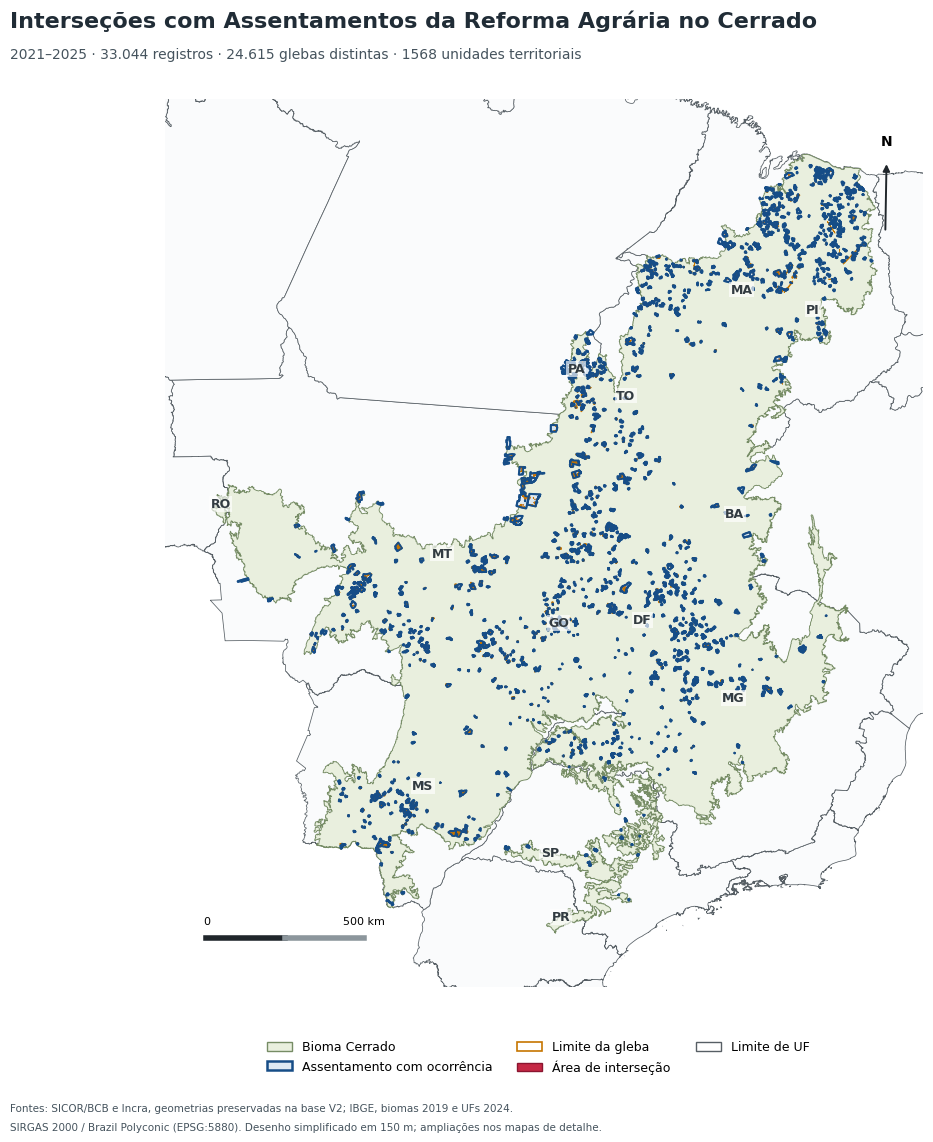

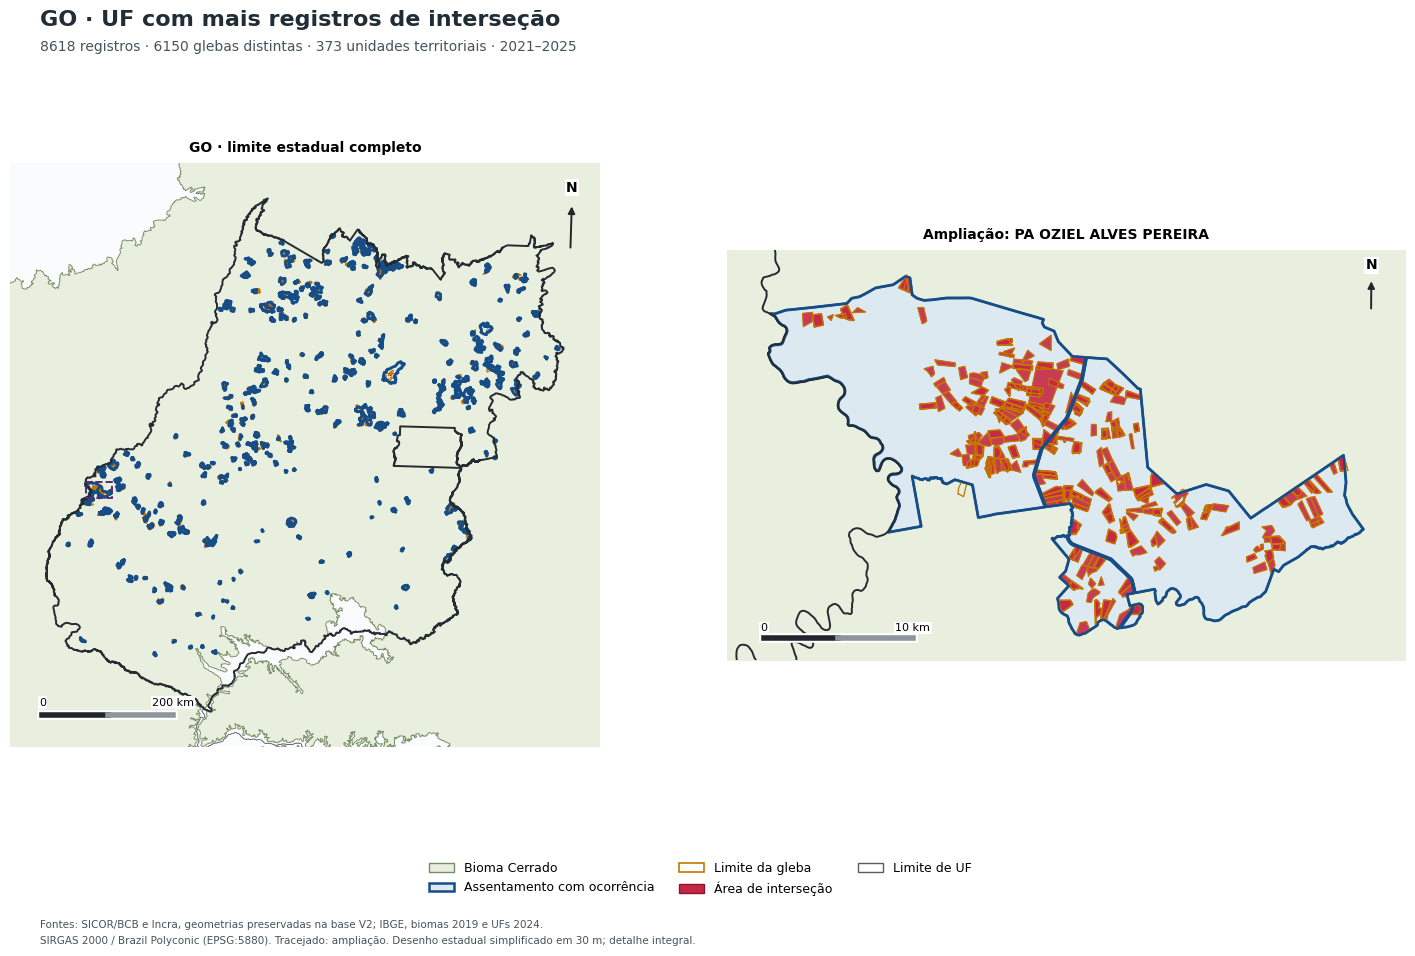

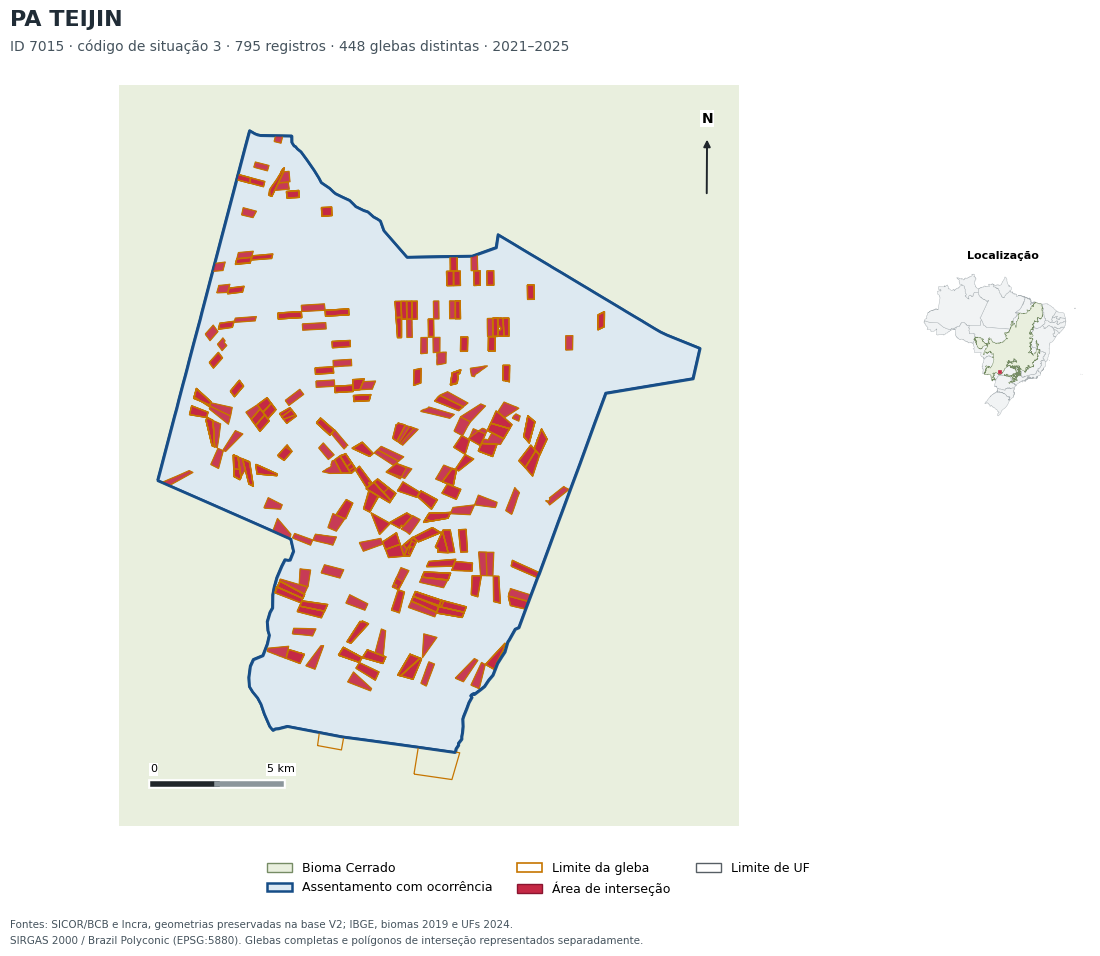

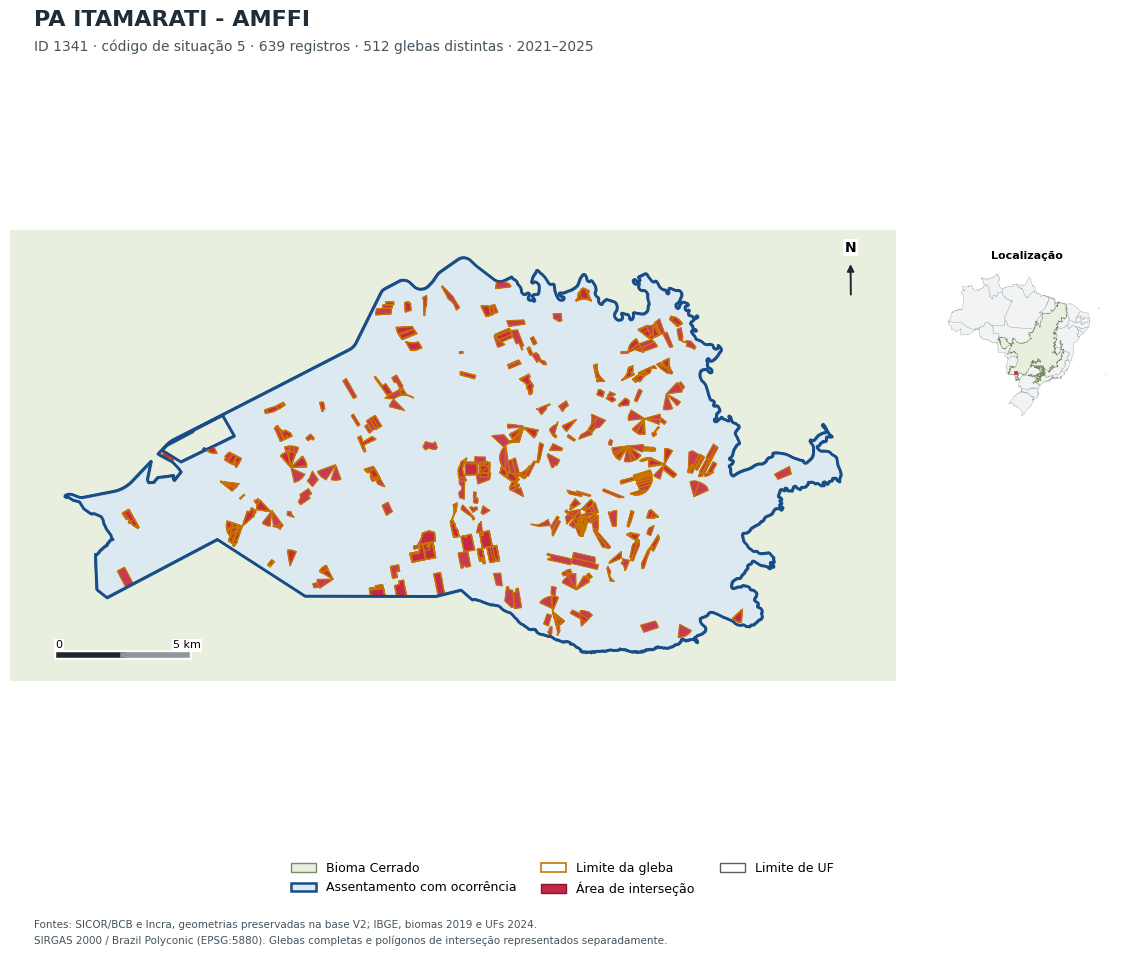

In [7]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.titleweight':'bold','savefig.facecolor':'white','svg.fonttype':'none'})
COR_ASSENT='#164D87';COR_GLEBA='#C67500';COR_INTER='#C52845';COR_CERRADO='#E9EFDE';COR_UF='#575F65'
mapas_gerados=[]
para_ll=Transformer.from_crs(CRS_ANALISE,4674,always_xy=True)
para_xy=Transformer.from_crs(4674,CRS_ANALISE,always_xy=True)
geod=Geod(ellps='GRS80')

def serie(geom):return gpd.GeoSeries([geom],crs=CRS_ANALISE)
def enquadrar(ax,bounds,margem=0.07):
    a,b,c,d=map(float,bounds);w=max(c-a,1000);h=max(d-b,1000)
    ax.set_xlim(a-margem*w,c+margem*w);ax.set_ylim(b-margem*h,d+margem*h)
    ax.set_aspect('equal');ax.set_axis_off()

def perto(z,bounds):
    ids=z.sindex.query(box(*bounds),predicate='intersects')
    return z.iloc[ids]

def adornos(ax):
    a,c=ax.get_xlim();b,d=ax.get_ylim();w=c-a;h=d-b
    # Barra horizontal com comprimento calibrado geodesicamente no local.
    x0=a+0.055*w;y0=b+0.055*h
    lo,la=para_ll.transform(x0,y0);lo2,la2=para_ll.transform(x0+0.23*w,y0)
    _,_,dist=geod.inv(lo,la,lo2,la2)
    exp=10**math.floor(math.log10(max(dist,1)))
    length=max(v for v in [1*exp,2*exp,5*exp,10*exp,0.5*exp] if v<=dist)
    dx=0.23*w*length/dist
    ax.plot([x0,x0+dx],[y0,y0],color='white',lw=7,zorder=30)
    ax.plot([x0,x0+dx/2],[y0,y0],color='#20262B',lw=4,zorder=31)
    ax.plot([x0+dx/2,x0+dx],[y0,y0],color='#8C969C',lw=4,zorder=31)
    txt=f'{length/1000:g} km' if length>=1000 else f'{length:g} m'
    ax.text(x0,y0+0.016*h,'0',fontsize=8,zorder=32,ha='center',bbox=dict(fc='white',ec='none',pad=1))
    ax.text(x0+dx,y0+0.016*h,txt,fontsize=8,zorder=32,ha='center',bbox=dict(fc='white',ec='none',pad=1))
    # Norte verdadeiro no ponto de implantação da seta.
    nx=a+0.95*w;ny=b+0.85*h;lon,lat=para_ll.transform(nx,ny)
    xx,yy=para_xy.transform(lon,lat+0.1);vx=xx-nx;vy=yy-ny;norm=math.hypot(vx,vy)
    ex=nx+vx/norm*h*0.08;ey=ny+vy/norm*h*0.08
    ax.annotate('',xy=(ex,ey),xytext=(nx,ny),arrowprops=dict(arrowstyle='-|>',color='#20262B',lw=1.4),zorder=35)
    ax.text(ex,ey+0.015*h,'N',ha='center',va='bottom',weight='bold',fontsize=10,zorder=35,bbox=dict(fc='white',ec='none',pad=1))

def desenhar(ax,territorio_ids,gleba_ids,ocorrencias,bounds,escala='geral',estado=None):
    a,b,c,d=bounds;w=max(c-a,1000);h=max(d-b,1000)
    janela=box(a-.10*w,b-.10*h,c+.10*w,d+.10*h)
    bg=perto(ufs,janela.bounds).copy()
    bg.geometry=bg.geometry.intersection(janela)
    bg.plot(ax=ax,facecolor='#FAFBFC',edgecolor=COR_UF,linewidth=0.55,zorder=0)
    contexto=cerrado.intersection(janela)
    if not contexto.is_empty:serie(contexto).plot(ax=ax,facecolor=COR_CERRADO,edgecolor='#768C65',linewidth=0.65,zorder=1)
    if escala=='geral':
        ts=territorios.loc[territorios.unidade.isin(territorio_ids)];gs=glebas.loc[glebas.gleba.isin(gleba_ids)]
    else:
        tolerancia=SIMPLIFICACAO_ESTADO_M if escala=='estado' else 0
        ts=carregar_geometrias('territorio',territorio_ids,tolerancia)
        gs=carregar_geometrias('gleba',gleba_ids,tolerancia)
    # Cópias sobrepostas desenhadas uma vez; as contagens continuam usando todas as linhas.
    ocorrencias=ocorrencias[['geometry']].drop_duplicates('geometry').copy()
    if escala in ['geral','estado']:
        tol=SIMPLIFICACAO_GERAL_M if escala=='geral' else SIMPLIFICACAO_ESTADO_M
        ocorrencias.geometry=ocorrencias.geometry.simplify(tol,preserve_topology=True)
    if not ts.empty:ts.plot(ax=ax,facecolor='#DDE9F3',edgecolor=COR_ASSENT,linewidth=1.5 if escala=='geral' else 2.0,alpha=0.95,zorder=3)
    if not ocorrencias.empty:ocorrencias.plot(ax=ax,facecolor=COR_INTER,edgecolor='#8A1530',linewidth=0.35,alpha=0.90,zorder=5,rasterized=True)
    if not gs.empty:gs.boundary.plot(ax=ax,color=COR_GLEBA,linewidth=0.65 if escala=='geral' else 0.9,zorder=6,rasterized=True)
    # Redesenha o contorno do território sobre as interseções.
    if not ts.empty:ts.boundary.plot(ax=ax,color=COR_ASSENT,linewidth=1.2 if escala=='geral' else 1.65,zorder=7)
    if estado is not None:serie(estado).boundary.plot(ax=ax,color='#252C31',linewidth=1.4,zorder=7)
    enquadrar(ax,bounds);adornos(ax)

handles=[Patch(facecolor=COR_CERRADO,edgecolor='#768C65',label='Bioma Cerrado'),
         Patch(facecolor='#DDE9F3',edgecolor=COR_ASSENT,linewidth=1.8,label='Assentamento com ocorrência'),
         Patch(facecolor='none',edgecolor=COR_GLEBA,linewidth=1.2,label='Limite da gleba'),
         Patch(facecolor=COR_INTER,edgecolor='#8A1530',label='Área de interseção'),
         Patch(facecolor='none',edgecolor=COR_UF,linewidth=1,label='Limite de UF')]

def finalizar(fig,nome,titulo,subtitulo,nota=''):
    fig.suptitle(titulo,x=0.06,y=0.965,ha='left',fontsize=16,weight='bold',color='#202C36')
    fig.text(0.06,0.924 if '\n' not in titulo else 0.89,subtitulo,ha='left',fontsize=10,color='#45535D')
    fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(0.5,0.068),ncol=3,frameon=False,fontsize=9)
    fonte='Fontes: SICOR/BCB e Incra, geometrias preservadas na base V2; IBGE, biomas 2019 e UFs 2024.'
    if ARQUIVO_UFS or ARQUIVO_BIOMAS:fonte='Fontes: SICOR/BCB e Incra (base V2); '+FONTE_BIOMAS+'; '+FONTE_UFS+'.'
    fig.text(0.06,0.047,fonte,fontsize=7.5,color='#45535D')
    fig.text(0.06,0.031,'SIRGAS 2000 / Brazil Polyconic (EPSG:5880). '+nota,fontsize=7.5,color='#45535D')
    fig.subplots_adjust(left=0.04,right=0.97,bottom=0.15,top=0.89 if '\n' not in titulo else 0.845)
    for ext in FORMATOS:fig.savefig(SAIDA/'mapas'/f'{nome}.{ext}',dpi=DPI)
    mapas_gerados.append({'arquivo':nome,'titulo':titulo,'subtitulo':subtitulo,'nota':nota})
    if MOSTRAR_FIGURAS:plt.show()
    plt.close(fig)

fig,ax=plt.subplots(figsize=(12,12))
desenhar(ax,territorios.unidade,glebas.gleba,x,cerrado.bounds)
for _,u in ufs.loc[ufs.intersects(cerrado)].iterrows():
    pt=u.geometry.intersection(cerrado).representative_point()
    ax.text(pt.x,pt.y,u.UF,fontsize=9,weight='bold',color='#323B41',ha='center',zorder=20,
            bbox=dict(fc='white',ec='none',alpha=0.65,pad=1))
finalizar(fig,'01_cerrado_assentamentos_contornos_reforcados','Interseções com Assentamentos da Reforma Agrária no Cerrado',
          f"2021–2025 · {len(x):,} registros · {len(glebas):,} glebas distintas · {len(territorios)} unidades territoriais".replace(',','.'),
          f'Desenho simplificado em {SIMPLIFICACAO_GERAL_M} m; ampliações nos mapas de detalhe.')

# Estado completo à esquerda e ampliação do território com mais registros nesse estado à direita.
z=xuf.loc[xuf.UF.eq(UF_TOP)].copy();estado=ufs.loc[ufs.UF.eq(UF_TOP)].geometry.iloc[0]
rank_local=z.groupby('unidade').linha.nunique().rename('n').reset_index().merge(territorios[['unidade','nome']],on='unidade')
top_local=rank_local.sort_values(['n','nome','unidade'],ascending=[False,True,True]).iloc[0].unidade
zl=z.loc[z.unidade.eq(top_local)];territorio_local=carregar_geometrias('territorio',[top_local]).iloc[0]
gl_local=carregar_geometrias('gleba',zl.gleba)
bdet=gpd.GeoSeries([territorio_local.geometry,*gl_local.geometry],crs=CRS_ANALISE).total_bounds
fig,axs=plt.subplots(1,2,figsize=(15,10),gridspec_kw={'width_ratios':[1,1.15]})
desenhar(axs[0],z.unidade.unique(),z.gleba.unique(),z,estado.bounds,'estado',estado)
desenhar(axs[1],[top_local],zl.gleba.unique(),zl,bdet,'detalhe',estado)
axs[0].set_title(f'{UF_TOP} · limite estadual completo',fontsize=10,pad=8)
axs[1].set_title('Ampliação: '+'\n'.join(textwrap.wrap(territorio_local['nome'],width=44)),fontsize=10,pad=8)
a,b,c,e=bdet;axs[0].add_patch(Rectangle((a,b),c-a,e-b,fill=False,edgecolor='#5B296F',linewidth=1.4,linestyle='--',zorder=25))
finalizar(fig,'02_uf_mais_casos_com_ampliacao',f'{UF_TOP} · UF com mais registros de interseção',
          f'{z.linha.nunique()} registros · {z.gleba.nunique()} glebas distintas · {z.unidade.nunique()} unidades territoriais · 2021–2025',
          f'Tracejado: ampliação. Desenho estadual simplificado em {SIMPLIFICACAO_ESTADO_M} m; detalhe integral.')

for pos,ident in enumerate(TOP_TERRITORIOS,1):
    t=carregar_geometrias('territorio',[ident]).iloc[0];zi=x.loc[x.unidade.eq(ident)]
    gi=carregar_geometrias('gleba',zi.gleba)
    limites=gpd.GeoSeries([t.geometry,*gi.geometry],crs=CRS_ANALISE).total_bounds
    fig=plt.figure(figsize=(12,10));ax=fig.add_subplot(1,5,(1,4))
    desenhar(ax,[ident],gi.gleba,zi,limites,'detalhe')
    # Limites estaduais, quando presentes no enquadramento, sempre visíveis.
    limites_uf=perto(ufs,limites).boundary.intersection(box(*limites))
    limites_uf=limites_uf.loc[~limites_uf.is_empty]
    if not limites_uf.empty:limites_uf.plot(ax=ax,color='#252C31',linewidth=0.8,zorder=7)
    # Miniatura em espaço próprio, fora do mapa principal e da seta norte.
    # O painel principal de detalhe utiliza as geometrias integrais.
    en=fig.add_axes([0.815,0.50,0.145,0.26])
    ufs.geometry.simplify(1500,preserve_topology=True).plot(ax=en,facecolor='#F1F3F4',edgecolor='#AAB1B5',linewidth=0.3)
    serie(cerrado.simplify(1500,preserve_topology=True)).plot(ax=en,facecolor=COR_CERRADO,edgecolor='#768C65',linewidth=0.3)
    # Retângulo de localização no Brasil; não representa a área da gleba.
    a,b,c,e=limites;en.add_patch(Rectangle((a,b),max(c-a,80000),max(e-b,80000),fill=False,edgecolor=COR_INTER,linewidth=1.2))
    en.set_axis_off();en.set_title('Localização',fontsize=8)
    m=por_territorio.loc[por_territorio.unidade.eq(ident)].iloc[0]
    titulo='\n'.join(textwrap.wrap(t['nome'],width=62))
    finalizar(fig,f'{pos+2:02d}_assentamento_{re.sub(r"[^A-Za-z0-9_-]","_",str(ident))}_detalhe',titulo,
       f"ID {ident} · código de situação {t.situacao_codigo} · {m.registros} registros · {m.glebas} glebas distintas · 2021–2025",
       'Glebas completas e polígonos de interseção representados separadamente.')


## 8. Exportar tabelas, legendas e síntese

Tabela completa por assentamento em CSV, Excel e HTML; tabela parcial das 20 primeiras unidades; tabelas por categoria de produtor, por ano e por assentamento × categoria; códigos de situação sem interpretação; conferências e textos para a reescrita do subcapítulo. A área de união geral e as contagens distintas não são somas das unidades.

In [8]:
def br(v,casas=0):
    if pd.isna(v):return 'Não informado'
    return f'{float(v):,.{casas}f}'.replace(',','X').replace('.',',').replace('X','.')
cols=['unidade','nome','situacao_codigo','uf_territorio','registros','glebas','refs','area_acumulada_ha','area_uniao_ha']
tab=por_territorio[cols].copy()
tot={'unidade':'TOTAL','nome':'Conjunto completo','situacao_codigo':'—','uf_territorio':'—',**geral}
tab=pd.concat([tab,pd.DataFrame([{k:tot[k] for k in cols}])],ignore_index=True)
for c in ['registros','glebas','refs']:tab[c]=tab[c].map(br)
for c in ['area_acumulada_ha','area_uniao_ha']:tab[c]=tab[c].map(lambda v:br(v,2))
tab.columns=['ID interno','Assentamento','Código de situação','UF informada','Registros','Glebas distintas','REF_BACEN distintos','Área acumulada (ha)','Área da união (ha)']
nota=('Fonte: elaborado pelo autor com base nas interseções SICOR × assentamentos/Incra, versão 2, e conferências desta execução. '
      'Cada registro é uma linha original. Unidades são agrupadas por ASSENT_ID_INTERNO. '
      'Contagens distintas e áreas de união são recalculadas; não somadas entre assentamentos ou categorias. '
      'UF informada: ASSENT_UF. Código de situação: ASSENT_FASE, sem tradução. Áreas em EPSG:5880.')
def tabela_html(t,titulo,arquivo,nota_extra=''):
    from html import escape
    s=('<!doctype html><html lang="pt-BR"><meta charset="utf-8"><title>'+escape(titulo)+
       '</title><style>body{font:12px Arial;margin:24px}table{border-collapse:collapse;width:100%}'
       'th,td{padding:6px;border:1px solid #bbb}th{background:#e4edf4}p{line-height:1.5}'
       '@media print{thead{display:table-header-group}tr{break-inside:avoid}@page{size:A4 landscape;margin:15mm}}</style>'
       '<h2>'+escape(titulo)+'</h2>'+t.to_html(index=False,escape=True,border=0)+'<p>'+escape(nota+' '+nota_extra)+'</p></html>')
    (SAIDA/'tabelas'/arquivo).write_text(s,encoding='utf-8')
tabela_html(tab,'Interseções por assentamento — Cerrado, 2021–2025','tabela_completa_para_word.html')
tabela_html(tab.iloc[:-1].head(20),'20 assentamentos com mais registros — Cerrado, 2021–2025',
    'tabela_20_primeiros_para_word.html','Tabela parcial. O conjunto completo está no arquivo complementar.')
csv(por_territorio.head(20),'20_assentamentos_com_mais_registros.csv')
pc=por_categoria[['categoria_produtor','registros','refs','soma_valores_linhas']].copy()
pc=pd.concat([pc,pd.DataFrame([{'categoria_produtor':'TOTAL','registros':geral['registros'],'refs':geral['refs'],'soma_valores_linhas':geral['soma_valores_linhas']}])],ignore_index=True)
for c in ['registros','refs']:pc[c]=pc[c].map(br)
pc.soma_valores_linhas=pc.soma_valores_linhas.map(lambda v:br(v,2))
pc.columns=['Categoria de produtor','Registros','REF_BACEN distintos','Valor somado nas linhas (R$)']
tabela_html(pc,'Interseções por categoria de produtor — Cerrado, 2021–2025','tabela_categoria_produtor_para_word.html',
    'Soma financeira das linhas, sem deduplicação por operação ou proporcionalização à área intersectada.')
controle_rank_unidades=pd.DataFrame({'unidade':['7015','1341'],'registros_resumo_v2':[795,639],
    'nome_resumo_v2':['PA TEIJIN','PA ITAMARATI - AMFFI']})
controle_rank_unidades=controle_rank_unidades.merge(por_territorio[['unidade','nome','registros','posicao']],on='unidade',how='left')
controle_rank_unidades['diferenca']=controle_rank_unidades.registros-controle_rank_unidades.registros_resumo_v2
csv(controle_rank_unidades,'conferencia_unidades_destaque_v2.csv')

with pd.ExcelWriter(SAIDA/'tabelas'/'Totais_Assentamentos_5_5_4.xlsx',engine='openpyxl') as writer:
    for nome,z in [('Por assentamento',por_territorio),('20 primeiros',por_territorio.head(20)),
        ('Total geral',pd.DataFrame([geral])),('Ranking UFs',por_uf),('Categoria produtor',por_categoria),
        ('Por ano',por_ano),('Assentamento x categoria',por_assentamento_categoria),('Codigos situacao',por_situacao),
        ('Identificacao',auditoria_nomes),('Auditoria UF',auditoria_uf),('Padronizacao produtor',auditoria_produtor),
        ('Conferencia areas UF',conferencia_uf),('Conferencia ranking UF',controle_rank_uf),
        ('Conferencia destaques',controle_rank_unidades),('Conferencia V2',conferencia),
        ('Unidades V2',controle_unidades),('Categoria V2',controle_produtor),('Reparos desenho',reparos)]:
        z.to_excel(writer,sheet_name=nome,index=False)
        ws=writer.sheets[nome];ws.freeze_panes='A2';ws.auto_filter.ref=ws.dimensions
        from openpyxl.styles import Font,PatternFill
        for cell in ws[1]:cell.font=Font(bold=True,color='FFFFFF');cell.fill=PatternFill('solid',fgColor='164D87')
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width=min(52,max(14,max(len(str(c.value or '')) for c in col)+2))
            if any(v in str(col[0].value) for v in ['area_','soma_valores']):
                for cell in col[1:]:cell.number_format='#,##0.00'
    pd.DataFrame({'Notas':[nota,
        'Camada de controle territorial; não representa impedimento automático ao crédito.',
        'Categoria do produtor é atributo administrativo de cada linha; não é modalidade do assentamento.',
        'O resumo V2 por unidade contém subdivisões por categoria. Só registros e área acumulada foram somados para conferir esse resumo.',
        'Para IDs com várias linhas no resumo, glebas distintas e união foram recalculadas; não há referência única agregável para comparar.',
        'Um registro pode contar em mais de uma UF; cada linha conta uma vez por UF com interseção de área positiva.',
        'Reparos de validade após reprojeção são exclusivos das geometrias de desenho e ficam registrados. Não alteram as interseções analíticas.',
        'A tabela completa inclui a soma dos valores das linhas, sujeita a repetição de valores administrativos.'
    ]}).to_excel(writer,sheet_name='Leia-me',index=False)

texto=(f"Foram examinados {br(geral['registros'])} registros, relacionados a {br(geral['glebas'])} glebas distintas, "
       f"{br(geral['territorios'])} assentamentos e {br(geral['refs'])} referências BACEN. "
       f"A área acumulada foi de {br(geral['area_acumulada_ha'],2)} ha; a união geométrica, de {br(geral['area_uniao_ha'],2)} ha. "
       f"A soma dos valores presentes nas linhas foi de R$ {br(geral['soma_valores_linhas'],2)}.\n\n"
       f"A UF com mais registros foi {UF_TOP}, com {br(por_uf.iloc[0].registros)} ocorrências. "
       "Cada linha original foi contada uma vez por UF com área positiva de interseção.\n\n"
       "Assentamentos selecionados para os mapas individuais, em ordem de registros:\n")
for _,r in por_territorio.head(NUMERO_TERRITORIOS_DETALHE).iterrows():
    texto+=f"- {r['nome']} (ID {r.unidade}; código de situação {r.situacao_codigo}; UF do atributo: {r.uf_territorio}): {br(r.registros)} registros, {br(r.glebas)} glebas, {br(r.refs)} REF_BACEN e {br(r.area_uniao_ha,2)} ha de união.\n"
texto+='\nDistribuição por categoria de produtor:\n'
for _,r in por_categoria.iterrows():
    texto+=f"- {r.categoria_produtor}: {br(r.registros)} registros, {br(r.refs)} referências BACEN e R$ {br(r.soma_valores_linhas,2)} somados nas linhas.\n"
texto+=(f"\nA soma estadual foi de {br(por_uf.registros.sum())} ocorrências; {br(len(linhas_multiuf))} registros aparecem em mais de uma UF. "
        "O total global permanece sendo o número de linhas originais.\n"
        "A tabela completa consolida cada assentamento por ID. No resumo anterior, uma unidade podia ocupar várias linhas por categoria de produtor. "
        "Glebas, referências distintas e união foram recalculadas nos registros, sem somar medidas não aditivas dessas subdivisões.\n\n"
        "Os assentamentos são tratados como controle territorial, não como impedimento automático ao crédito. "
        "O código de situação foi preservado sem atribuição de significado jurídico. A categoria do produtor não substitui a verificação de sua condição cadastral. "
        "A soma financeira das linhas pode repetir valores e não corresponde a crédito exclusivo da área intersectada.\n")
texto+=f"\nForam documentados {len(reparos)} eventos de reparo cartográfico após reprojeção; consulte a tabela de reparos. Nenhuma linha foi eliminada em razão desses ajustes.\n"
if not conferencia.confere.all():texto+='\nATENÇÃO: há divergências com os totais gerais de referência. Consulte a conferência antes de atualizar o texto.\n'
if not controle_unidades.empty and not controle_unidades.confere.all():texto+='\nATENÇÃO: há divergências nas métricas comparáveis de unidades. Consulte Unidades V2.\n'
(SAIDA/'resultados_para_resposta_ao_orientador.txt').write_text(texto,encoding='utf-8')
legendas=[]
for m in mapas_gerados:
    legendas.append(m['arquivo']+'\n'+m['titulo'].replace('\n',' ')+' — '+m['subtitulo']+'.\n'+m['nota']+
        '\nFonte: elaborado pelo autor com base no SICOR/BCB e nos limites dos assentamentos/Incra preservados na versão 2; '+FONTE_BIOMAS+'; '+FONTE_UFS+'.\n')
(SAIDA/'legendas_das_figuras.txt').write_text('\n'.join(legendas),encoding='utf-8')
observacoes=[
    'Seleção da UF e dos dois assentamentos: número de registros, não maior área.',
    'A tabela integral tem uma linha por ASSENT_ID_INTERNO; nomes iguais não foram fundidos.',
    'O resumo V2 por unidade subdivide IDs por categoria de produtor. Não é uma tabela de geometrias únicas por assentamento.',
    'O campo TIPO_PRODUTOR_ANALISE não foi interpretado como tipo ou modalidade de assentamento.',
    'Os códigos de ASSENT_FASE não foram traduzidos sem dicionário documentado.',
    'As áreas e contagens distintas das subdivisões não foram somadas; a união e os identificadores distintos foram recalculados.',
    'A UF ASSENT_UF permanece como atributo; a seleção estadual usa a localização das interseções na malha IBGE 2024.',
    'Os mapas representam somente assentamentos com ocorrência na amostra e preservam o universo espacial da versão 2.',
    'A simplificação é exclusiva do desenho geral/estadual; mapas de detalhe usam geometrias sem essa simplificação.',
    'Reparos cartográficos após reprojeção não devem ser contabilizados como polígonos inválidos na origem.',
    'A categoria de produtor não comprova, isoladamente, enquadramento cadastral como beneficiário do assentamento.',
    'A interseção com assentamentos não foi convertida em irregularidade ou impedimento automático ao crédito.'
]
(SAIDA/'observacoes_para_revisao_do_subcapitulo.txt').write_text('\n'.join(observacoes),encoding='utf-8')
print(texto)


Foram examinados 33.044 registros, relacionados a 24.615 glebas distintas, 1.568 assentamentos e 26.281 referências BACEN. A área acumulada foi de 646.622,73 ha; a união geométrica, de 291.757,19 ha. A soma dos valores presentes nas linhas foi de R$ 5.892.958.982,97.

A UF com mais registros foi GO, com 8.618 ocorrências. Cada linha original foi contada uma vez por UF com área positiva de interseção.

Assentamentos selecionados para os mapas individuais, em ordem de registros:
- PA TEIJIN (ID 7015; código de situação 3; UF do atributo: MS): 795 registros, 448 glebas, 793 REF_BACEN e 3.844,22 ha de união.
- PA ITAMARATI - AMFFI (ID 1341; código de situação 5; UF do atributo: MS): 639 registros, 512 glebas, 469 REF_BACEN e 2.409,15 ha de união.

Distribuição por categoria de produtor:
- Pronaf: 29.475 registros, 23.703 referências BACEN e R$ 2.052.524.555,38 somados nas linhas.
- Pronamp: 1.925 registros, 1.478 referências BACEN e R$ 617.065.673,85 somados nas linhas.
- Demais Produtores

## 9. Metadados, ZIP e pasta dos resultados
Compartilhe o ZIP ou a pasta desta execução para a reescrita do subcapítulo. O cache reduzido fica na pasta `_cache`, fora do ZIP. Se a conferência indicar divergências, utilize as tabelas de diagnóstico antes de substituir os números do texto.

In [9]:
metadados={'execucao_utc':datetime.now(timezone.utc).isoformat(),'origens':ORIGENS,'crs_wkt':CRS_WKT,'crs_calculo':CRS_ANALISE,
 'fontes_contexto':{'ufs':FONTE_UFS,'biomas':FONTE_BIOMAS},'colunas':C,'anos':ANOS,'deduplicacao_analitica':False,
 'unidade_caso':'Linha original da base espacial V2','criterio_selecao':'Quantidade de registros decrescente; desempate por nome/ID ou sigla UF',
 'uf_selecionada':UF_TOP,'territorios_selecionados':TOP_TERRITORIOS,'totais':{k:float(v) if isinstance(v,(np.floating,np.integer)) else v for k,v in geral.items()},
 'contexto_territorios':'Somente assentamentos com ocorrência; limites da V2. Desenho geral/estadual simplificado, detalhe integral'
 ,'simplificacao_desenho_m':{'geral':SIMPLIFICACAO_GERAL_M,'estado':SIMPLIFICACAO_ESTADO_M,'detalhe':0}
 ,'cache':str(BANCO),'identificacao_base':'caminho, bytes e mtime_ns; não é hash integral','mapas':mapas_gerados,'coluna_nome':C['nome'],'referencia_rank_unidades':{'7015':795,'1341':639},'papel_camada':'Controle territorial; não indica impedimento automático ao crédito',
 'reparos_desenho':reparos.to_dict('records'),'categoria_produtor_coluna':C['produtor_original'],
 'resumo_v2_fracionado_por_categoria':True,'divergencias_uf_atributo':int((~auditoria_uf.uf_informada_inclui_uf_espacial).sum()),
 'diferenca_corte_estadual_ha':residuo,'confere_totais_referencia':bool(conferencia.confere.all()),
 'versoes':{'python':platform.python_version(),'pandas':pd.__version__,'geopandas':gpd.__version__,'shapely':shapely.__version__}}
(SAIDA/'metadados.json').write_text(json.dumps(metadados,ensure_ascii=False,indent=2),encoding='utf-8')
zip_final=SAIDA/'Resultados_Assentamentos_5_5_4.zip'
with zipfile.ZipFile(zip_final,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(SAIDA.rglob('*')):
        if p.is_file() and p!=zip_final:z.write(p,arcname=str(p.relative_to(SAIDA)))
print('Resultados salvos em:',SAIDA)
print('ZIP:',zip_final)
if BAIXAR_ZIP:
    from google.colab import files
    files.download(str(zip_final))


Resultados salvos em: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/complementos_assentamentos_5_5_4/20260918_134855_119125
ZIP: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/complementos_assentamentos_5_5_4/20260918_134855_119125/Resultados_Assentamentos_5_5_4.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Produtos para o subcapítulo 5.5.4

- `tabelas/totais_por_assentamento_completo.csv` e planilha Excel: uma linha por assentamento, com registros, glebas distintas, REF_BACEN distintos, áreas e soma financeira das linhas.
- `tabelas/totais_por_categoria_produtor.csv`: reprodução da tabela por categoria com valores efetivamente calculados.
- `mapas/01_cerrado_assentamentos_contornos_reforcados`, `02_uf_mais_casos_com_ampliacao` e dois mapas individuais: PNG 400 dpi, PDF e SVG.
- `resultados_para_resposta_ao_orientador.txt`, `legendas_das_figuras.txt` e `observacoes_para_revisao_do_subcapitulo.txt`: números, critérios e limitações para o texto.
- `tabelas/reparos_geometrias_desenho.csv`: ajustes cartográficos após reprojeção, sem substituição das interseções analíticas.

**Leitura dos resultados:** a categoria Pronaf/Pronamp/Demais Produtores é atributo dos registros administrativos; não identifica por si só a condição jurídica ou cadastral do beneficiário do assentamento. A presença de interseção é informação territorial a qualificar, não contagem automática de concessões irregulares. A soma monetária das linhas pode repetir valores de uma mesma operação.

Compartilhe a pasta da execução ou o ZIP final para preparar o Word do subcapítulo com os novos resultados e figuras.